In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models, Input
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import classification_report, confusion_matrix

In [2]:
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [3]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2531s 15us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Training labels: (50000, 1)
Testing labels: (10000, 1)


In [4]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

In [5]:
train_counts = np.bincount(y_train.flatten(), minlength=10)
test_counts = np.bincount(y_test.flatten(), minlength=10)

dataset_summary = pd.DataFrame({
    'Class': class_names,
    'Training Images': train_counts,
    'Testing Images': test_counts
})

dataset_summary

,Class,Training Images,Testing Images
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000


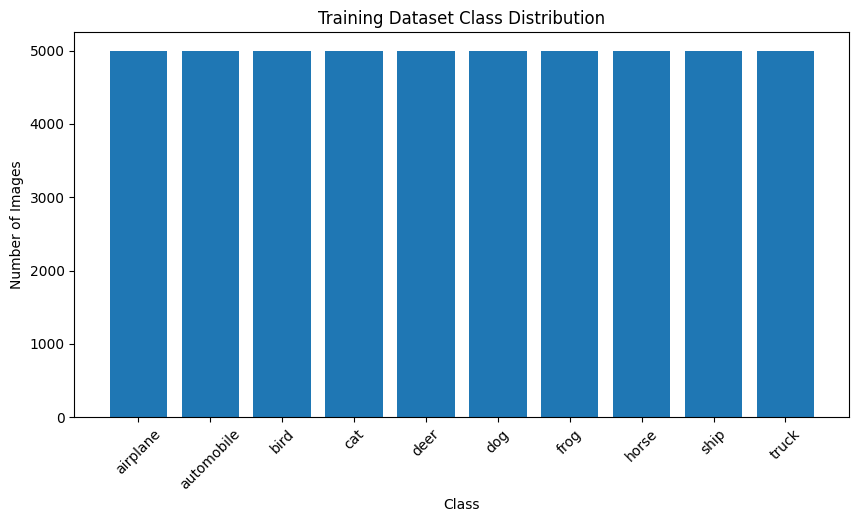

In [6]:
plt.figure(figsize=(10, 5))
plt.bar(class_names, train_counts)
plt.title('Training Dataset Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)
plt.show()

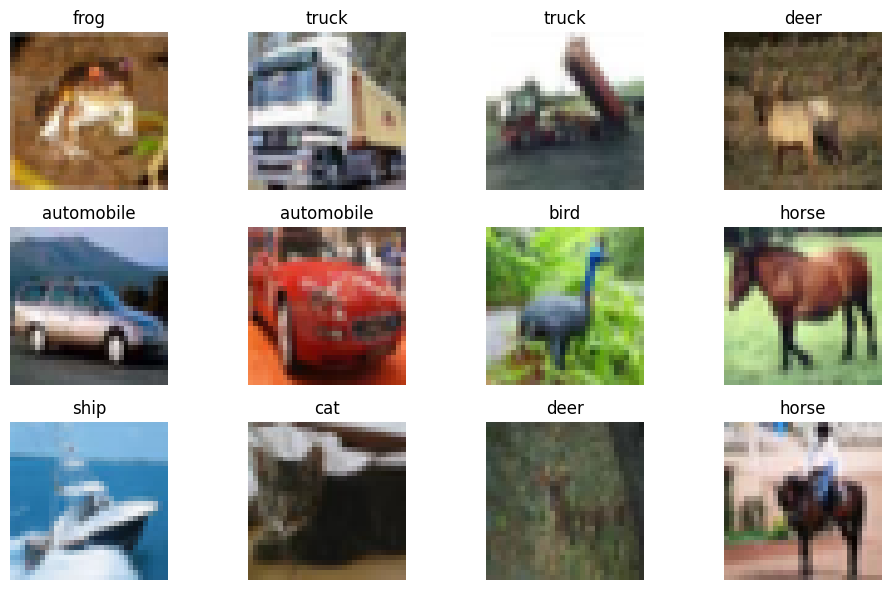

In [7]:
plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [10]:

basic_model = models.Sequential([
    Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

basic_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
basic_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [12]:
basic_history = basic_model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 60s 83ms/step - accuracy: 0.4301 - loss: 1.5771 - val_accuracy: 0.5432 - val_loss: 1.2946
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 56s 80ms/step - accuracy: 0.5728 - loss: 1.2128 - val_accuracy: 0.6124 - val_loss: 1.1203
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 83ms/step - accuracy: 0.6239 - loss: 1.0725 - val_accuracy: 0.6406 - val_loss: 1.0379
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 79s 79ms/step - accuracy: 0.6561 - loss: 0.9858 - val_accuracy: 0.6466 - val_loss: 1.0200
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 57s 80ms/step - accuracy: 0.6809 - loss: 0.9157 - val_accuracy: 0.6764 - val_loss: 0.9513
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 80ms/step - accuracy: 0.7027 - loss: 0.8532 - val_accuracy: 0.6820 - val_loss: 0.9160
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 57s 81ms/step - accuracy: 0.7234 - loss: 0.7968 - val_accuracy: 0.6884 - val_loss: 0.8981
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 56s 79ms/step - accuracy: 0.7376 - loss: 0.7516 - 

In [13]:
basic_loss, basic_accuracy = basic_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Basic CNN Accuracy:", round(basic_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6916 - loss: 1.0096
Basic CNN Accuracy: 69.16 %


In [14]:
model = models.Sequential([
    Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 358,218 (1.37 MB)

 Trainable params: 357,514 (1.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [17]:
history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 149s 207ms/step - accuracy: 0.4164 - loss: 1.7096 - val_accuracy: 0.4510 - val_loss: 1.5543 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - accuracy: 0.5565 - loss: 1.2422 - val_accuracy: 0.5802 - val_loss: 1.1966 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 201s 209ms/step - accuracy: 0.6164 - loss: 1.0926 - val_accuracy: 0.6492 - val_loss: 1.0024 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 201s 208ms/step - accuracy: 0.6515 - loss: 0.9925 - val_accuracy: 0.6878 - val_loss: 0.8895 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 145s 206ms/step - accuracy: 0.6777 - loss: 0.9252 - val_accuracy: 0.6616 - val_loss: 0.9450 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 147s 209ms/step - accuracy: 0.6982 - loss: 0.8748 - val_accuracy: 0.6712 - val_loss: 0.9902 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 144s 205ms/step - accura

In [18]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Enhanced CNN Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8064 - loss: 0.5600
Enhanced CNN Accuracy: 80.64 %


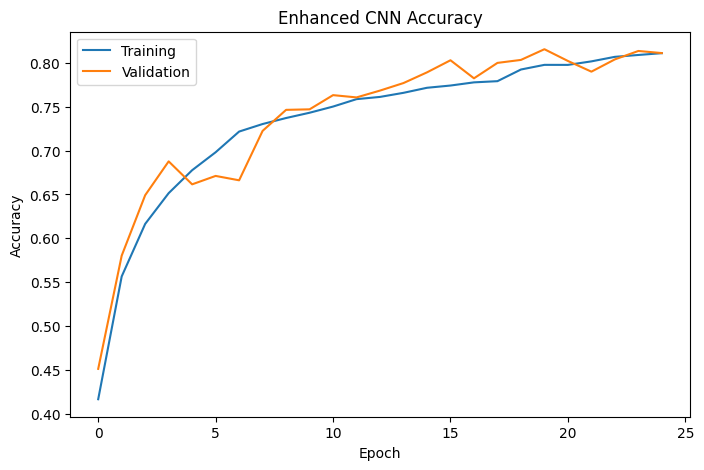

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Enhanced CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])
plt.show()

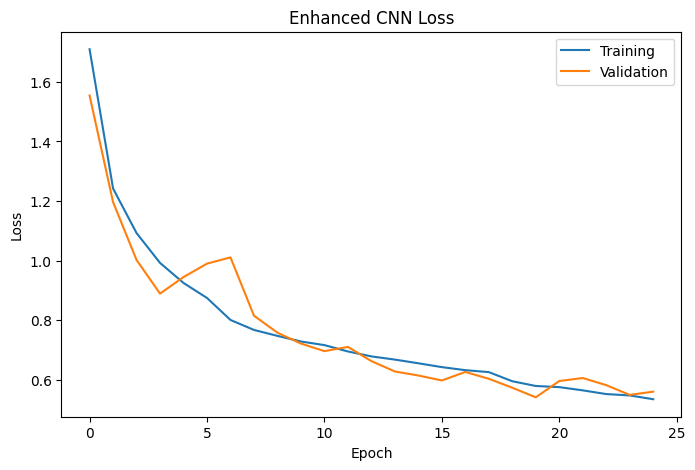

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Enhanced CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])
plt.show()

In [21]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = y_test.flatten()

print(classification_report(
    y_true,
    y_pred_classes,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step
              precision    recall  f1-score   support

    airplane       0.79      0.85      0.82      1000
  automobile       0.90      0.91      0.90      1000
        bird       0.77      0.70      0.73      1000
         cat       0.66      0.64      0.65      1000
        deer       0.77      0.79      0.78      1000
         dog       0.72      0.71      0.71      1000
        frog       0.82      0.89      0.85      1000
       horse       0.86      0.82      0.84      1000
        ship       0.88      0.91      0.89      1000
       truck       0.90      0.84      0.87      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.81     10000
weighted avg       0.81      0.81      0.81     10000



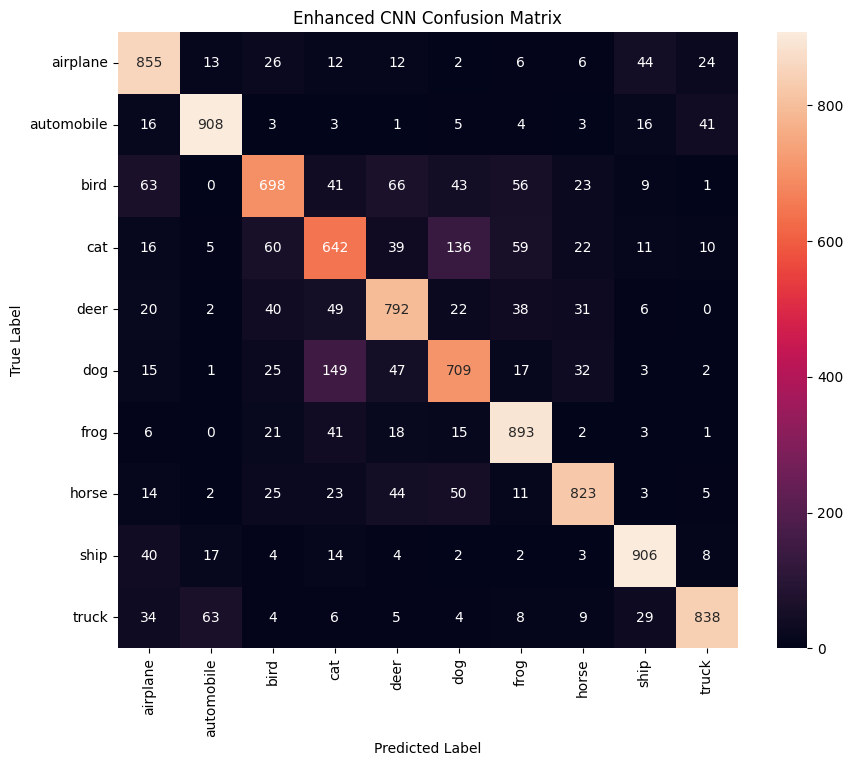

In [22]:
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Enhanced CNN Confusion Matrix')
plt.show()

In [23]:
print("Basic CNN Accuracy:", round(basic_accuracy * 100, 2), "%")
print("Enhanced CNN Accuracy:", round(test_accuracy * 100, 2), "%")
print("Improvement:", round((test_accuracy - basic_accuracy) * 100, 2), "%")

Basic CNN Accuracy: 69.16 %
Enhanced CNN Accuracy: 80.64 %
Improvement: 11.48 %


In [24]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

transfer_model = models.Sequential([
    Input(shape=(32, 32, 3)), # Input matches original CIFAR-10 image size
    layers.Resizing(96, 96),  # Resizes images to 96x96
    layers.Rescaling(1./127.5, offset=-1), # Preprocesses for MobileNetV2
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
transfer_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [26]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
transfer_history = transfer_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 359s 500ms/step - accuracy: 0.0989 - loss: 2.3085 - val_accuracy: 0.0976 - val_loss: 2.3028 - learning_rate: 0.0010
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 383s 502ms/step - accuracy: 0.0960 - loss: 2.3027 - val_accuracy: 0.0950 - val_loss: 2.3028 - learning_rate: 0.0010
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 355s 504ms/step - accuracy: 0.0992 - loss: 2.3027 - val_accuracy: 0.0976 - val_loss: 2.3028 - learning_rate: 5.0000e-04
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 386s 510ms/step - accuracy: 0.0979 - loss: 2.3027 - val_accuracy: 0.0950 - val_loss: 2.3027 - learning_rate: 5.0000e-04
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 378s 503ms/step - accuracy: 0.0975 - loss: 2.3026 - val_accuracy: 0.0950 - val_loss: 2.3028 - learning_rate: 2.5000e-04


In [28]:
transfer_loss, transfer_accuracy = transfer_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("MobileNetV2 Accuracy:", round(transfer_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 63s 201ms/step - accuracy: 0.1000 - loss: 2.3026
MobileNetV2 Accuracy: 10.0 %


In [29]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [30]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
fine_tune_history = transfer_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 543s 758ms/step - accuracy: 0.2607 - loss: 2.0535 - val_accuracy: 0.0950 - val_loss: 2.4236 - learning_rate: 1.0000e-05
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 533s 757ms/step - accuracy: 0.3630 - loss: 1.8078 - val_accuracy: 0.1056 - val_loss: 2.3942 - learning_rate: 1.0000e-05
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 531s 754ms/step - accuracy: 0.3940 - loss: 1.7185 - val_accuracy: 0.0958 - val_loss: 2.6528 - learning_rate: 5.0000e-06
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 571s 767ms/step - accuracy: 0.4112 - loss: 1.6787 - val_accuracy: 0.1322 - val_loss: 2.5467 - learning_rate: 5.0000e-06
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 537s 763ms/step - accuracy: 0.4270 - loss: 1.6438 - val_accuracy: 0.1058 - val_loss: 2.7779 - learning_rate: 2.5000e-06


In [32]:
fine_tune_loss, fine_tune_accuracy = transfer_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print(
    "Fine-Tuned MobileNetV2 Accuracy:",
    round(fine_tune_accuracy * 100, 2),
    "%"
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 65s 207ms/step - accuracy: 0.1000 - loss: 2.4240
Fine-Tuned MobileNetV2 Accuracy: 10.0 %


In [33]:
results = {
    'Basic CNN': basic_accuracy,
    'Enhanced CNN': test_accuracy,
    'MobileNetV2': transfer_accuracy,
    'Fine-Tuned MobileNetV2': fine_tune_accuracy
}

for name, accuracy in results.items():
    print(name + ":", round(accuracy * 100, 2), "%")

Basic CNN: 69.16 %
Enhanced CNN: 80.64 %
MobileNetV2: 10.0 %
Fine-Tuned MobileNetV2: 10.0 %


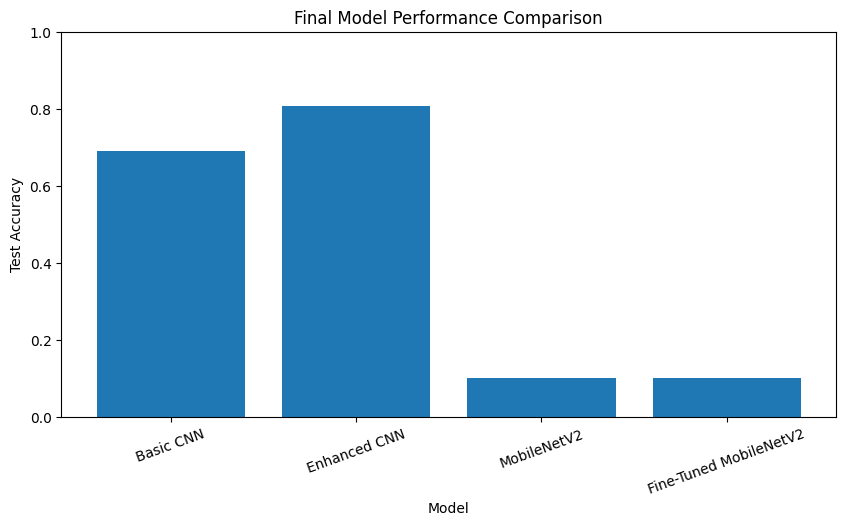

In [34]:
model_names = list(results.keys())
accuracies = list(results.values())

plt.figure(figsize=(10, 5))
plt.bar(model_names, accuracies)
plt.title('Final Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

In [35]:
best_model_name = max(results, key=results.get)
best_accuracy = results[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")

Best Model: Enhanced CNN
Best Accuracy: 80.64 %


In [36]:
final_predictions = transfer_model.predict(x_test)
final_pred_classes = np.argmax(final_predictions, axis=1)
final_true = y_test.flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 67s 209ms/step


In [37]:
print(classification_report(
    final_true,
    final_pred_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

    airplane       0.00      0.00      0.00      1000
  automobile       0.00      0.00      0.00      1000
        bird       0.00      0.00      0.00      1000
         cat       0.00      0.00      0.00      1000
        deer       0.10      1.00      0.18      1000
         dog       0.00      0.00      0.00      1000
        frog       0.00      0.00      0.00      1000
       horse       0.00      0.00      0.00      1000
        ship       0.00      0.00      0.00      1000
       truck       0.00      0.00      0.00      1000

    accuracy                           0.10     10000
   macro avg       0.01      0.10      0.02     10000
weighted avg       0.01      0.10      0.02     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


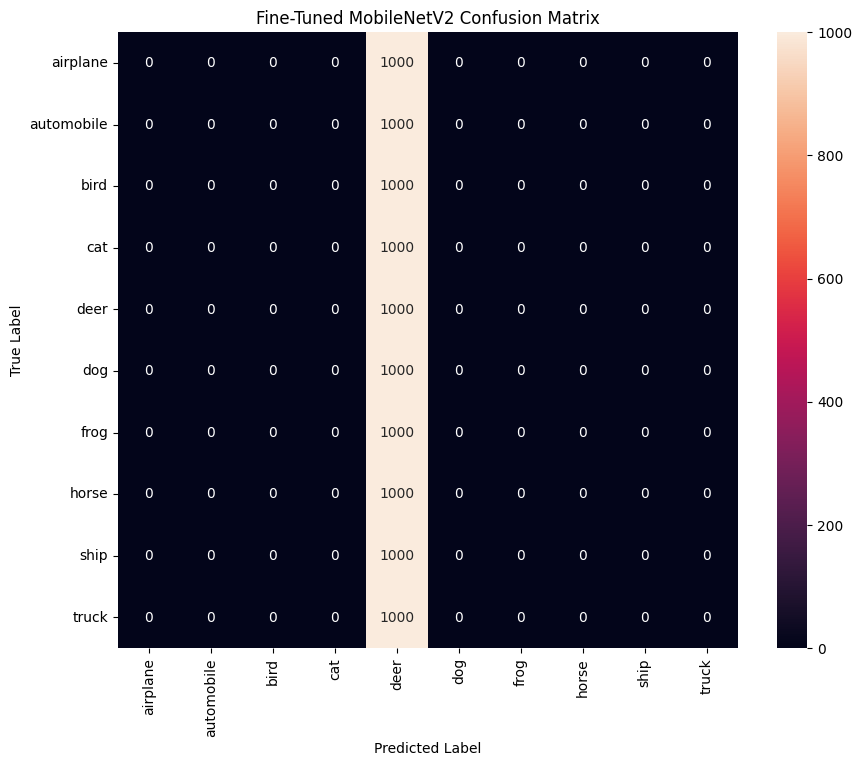

In [38]:
final_cm = confusion_matrix(
    final_true,
    final_pred_classes
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Fine-Tuned MobileNetV2 Confusion Matrix')
plt.show()

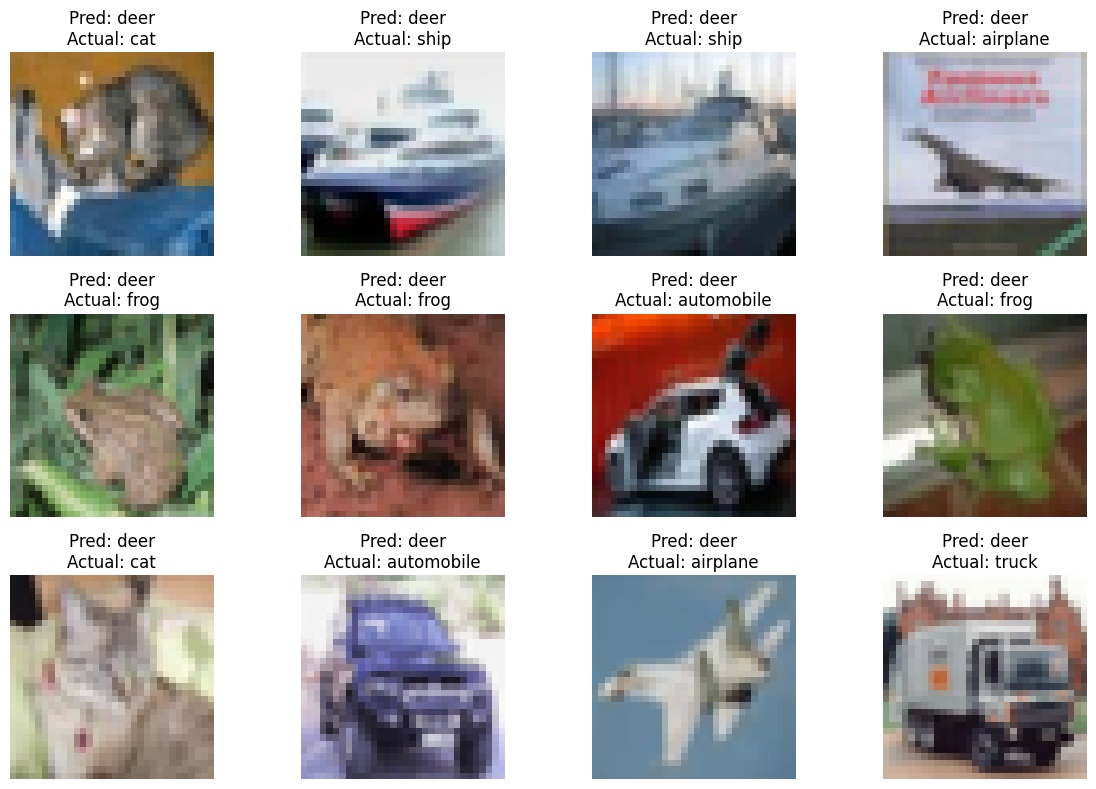

In [39]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])

    predicted = class_names[final_pred_classes[i]]
    actual = class_names[final_true[i]]

    plt.title(f"Pred: {predicted}\nActual: {actual}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [40]:
transfer_model.save('CIFAR10_Image_Classifier.keras')
print("Model saved successfully.")

Model saved successfully.


In [41]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = list(uploaded.keys())[0]

img = load_img(image_path, target_size=(96, 96))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

prediction = transfer_model.predict(img_array, verbose=0)[0]

predicted_class = np.argmax(prediction)
confidence = prediction[predicted_class] * 100

print("Predicted Class:", class_names[predicted_class])
print("Confidence:", round(confidence, 2), "%")

In [ ]:
display_image = load_img(image_path)

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.title(
    f"Prediction: {class_names[predicted_class]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis('off')
plt.show()

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

In [ ]:
def predict_image(image):
    image = image.convert('RGB')
    image = image.resize((96, 96))

    image_array = np.array(image).astype('float32')
    image_array = np.expand_dims(image_array, axis=0)
    image_array = preprocess_input(image_array)

    prediction = transfer_model.predict(
        image_array,
        verbose=0
    )[0]

    return {
        class_names[i]: float(prediction[i])
        for i in range(10)
    }

In [ ]:
demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="CIFAR-10 Image Classifier",
    description="Upload an image to classify it into one of the CIFAR-10 classes."
)

demo.launch()

In [ ]:
print("Basic CNN:", round(basic_accuracy * 100, 2), "%")
print("Enhanced CNN:", round(test_accuracy * 100, 2), "%")
print("MobileNetV2:", round(transfer_accuracy * 100, 2), "%")
print("Fine-Tuned MobileNetV2:", round(fine_tune_accuracy * 100, 2), "%")
print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")